# Procesamiento de lenguaje natural · Texto, frecuencias y TF-IDF

Primeros pasos del procesamiento de lenguaje natural con un corpus pequeño escrito aquí mismo: doce textos breves sobre Canarias. Se practica la tokenización con expresiones regulares (tildes, `ñ`, signos `¿` y `¡`), la normalización, las palabras vacías, un *stemmer* sencillo, los n-gramas, la ley de Zipf, la bolsa de palabras y TF-IDF, la similitud del coseno para buscar documentos y la extracción de palabras clave. Cada cálculo hecho a mano se compara con `collections`, `numpy` o `scikit-learn`.

In [1]:
import math
import re
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

CORPUS = [
    "El Teide es el pico más alto de España y se levanta en el centro de Tenerife.",
    "¿Sabías que el Teide es un volcán activo? Su última erupción fue en 1909.",
    "En Lanzarote los volcanes de Timanfaya dejaron un paisaje de lava, ceniza y cráteres.",
    "Las playas de Fuerteventura tienen arena blanca y un viento constante que atrae a los surfistas.",
    "La Graciosa es una isla tranquila: no hay carreteras asfaltadas y sus playas son de arena blanca.",
    "En La Gomera se conserva el silbo gomero, un lenguaje silbado que cruza barrancos y valles.",
    "El bosque de laurisilva de Garajonay, en La Gomera, guarda la humedad de los vientos alisios.",
    "¡Qué buenas están las papas arrugadas con mojo picón! Es el plato más típico de las islas.",
    "El gofio es harina de cereales tostados y se toma con leche, con caldo o junto a unas papas arrugadas.",
    "La Palma vivió en 2021 la erupción del volcán de Tajogaite, que cubrió de lava casas y plataneras.",
    "El Hierro produce casi toda su electricidad con los vientos alisios y el agua de la central de Gorona.",
    "Gran Canaria tiene dunas en Maspalomas, barrancos profundos y pueblos de montaña como Tejeda.",
]
print(len(CORPUS), "documentos")

12 documentos


## 1. Tokenizar con expresiones regulares

Escribir `tokenizar(texto)`, que devuelva una lista de *tokens*: palabras (con tildes, `ü` y `ñ`, y con guion interno como `norte-sur`), números (enteros o con decimales) y signos de puntuación sueltos, incluidos `¿`, `?`, `¡` y `!`. Comprobar que, al quitar los espacios, unir los tokens reconstruye el texto original, y probarla con el primer y el octavo documento.

In [2]:
LETRA = "a-zA-ZáéíóúüñÁÉÍÓÚÜÑ"
PATRON_TOKEN = re.compile(rf"[{LETRA}]+(?:-[{LETRA}]+)*|\d+(?:[.,]\d+)?|[¿?¡!.,;:()«»\"]")


def tokenizar(texto):
    return PATRON_TOKEN.findall(texto)


for doc in (CORPUS[1], CORPUS[7], "El trayecto norte-sur dura 1,5 horas, ¿no?"):
    print(tokenizar(doc))

for doc in CORPUS:
    assert "".join(tokenizar(doc)) == re.sub(r"\s+", "", doc)
assert tokenizar("¡Hola!") == ["¡", "Hola", "!"]

['¿', 'Sabías', 'que', 'el', 'Teide', 'es', 'un', 'volcán', 'activo', '?', 'Su', 'última', 'erupción', 'fue', 'en', '1909', '.']
['¡', 'Qué', 'buenas', 'están', 'las', 'papas', 'arrugadas', 'con', 'mojo', 'picón', '!', 'Es', 'el', 'plato', 'más', 'típico', 'de', 'las', 'islas', '.']
['El', 'trayecto', 'norte-sur', 'dura', '1,5', 'horas', ',', '¿', 'no', '?']


## 2. Normalizar: minúsculas y tildes

Crear `normalizar(palabra)`, que pase a minúsculas y quite tildes y diéresis pero conserve la `ñ` (es una letra distinta en español). Hacerlo con `unicodedata` (descomponer en NFD y quitar las marcas combinantes salvo la tilde de la `ñ`) y comprobarlo con una segunda versión basada en `str.maketrans` sobre todas las palabras del corpus.

In [3]:
def normalizar(palabra):
    descompuesta = unicodedata.normalize("NFD", palabra.lower())
    sin_marcas = re.sub(r"(?<!n)̃|[̀-̂̄-ͯ]", "", descompuesta)
    return unicodedata.normalize("NFC", sin_marcas)


TABLA = str.maketrans("áéíóúüàèìòù", "aeiouuaeiou")


def normalizar_tabla(palabra):
    return palabra.lower().translate(TABLA)


ejemplos = ["Volcán", "Pingüino", "ESPAÑA", "Ñame", "Tajogaite", "café"]
print({p: normalizar(p) for p in ejemplos})

palabras = [t for doc in CORPUS for t in tokenizar(doc) if t[0].isalpha()]
assert all(normalizar(p) == normalizar_tabla(p) for p in palabras + ejemplos)
assert normalizar("ESPAÑA") == "españa"

{'Volcán': 'volcan', 'Pingüino': 'pinguino', 'ESPAÑA': 'españa', 'Ñame': 'ñame', 'Tajogaite': 'tajogaite', 'café': 'cafe'}


## 3. Palabras vacías

Las palabras vacías (*stopwords*) son las muy frecuentes que apenas aportan significado: artículos, preposiciones, conjunciones… Definir una lista propia y escribir `terminos(texto)`, que tokenice, se quede solo con las palabras, las normalice y quite las vacías. Mostrar qué porcentaje de las palabras del corpus eran vacías y las diez más frecuentes antes y después de filtrarlas.

In [4]:
VACIAS = set(
    "a al algo con como de del el en es esta estan fue ha hay la las lo los mas me muy no o para por que "
    "se si son su sus tiene tienen un una uno y ya sabias qué".split()
)
VACIAS = {normalizar(v) for v in VACIAS}


def palabras_normalizadas(texto):
    return [normalizar(t) for t in tokenizar(texto) if t[0].isalpha()]


def terminos(texto):
    return [p for p in palabras_normalizadas(texto) if p not in VACIAS]


todas = [p for doc in CORPUS for p in palabras_normalizadas(doc)]
utiles = [p for doc in CORPUS for p in terminos(doc)]
print(f"Palabras: {len(todas)}; vacías: {1 - len(utiles) / len(todas):.0%}")
print("Antes: ", Counter(todas).most_common(10))
print("Después:", Counter(utiles).most_common(10))
assert len(utiles) == sum(p not in VACIAS for p in todas)

Palabras: 196; vacías: 49%
Antes:  [('de', 16), ('el', 10), ('y', 9), ('en', 7), ('la', 7), ('es', 5), ('que', 5), ('un', 4), ('los', 4), ('con', 4)]
Después: [('teide', 2), ('volcan', 2), ('erupcion', 2), ('lava', 2), ('playas', 2), ('arena', 2), ('blanca', 2), ('gomera', 2), ('barrancos', 2), ('vientos', 2)]


## 4. Un *stemmer* sencillo

Reducir cada palabra a una raíz aproximada quitando el sufijo más largo de una lista (plurales, `-mente`, `-ción`, `-dad`, terminaciones verbales…), siempre que queden al menos tres letras. Agrupar las palabras del corpus por raíz y mostrar los grupos con más de una forma. Comprobar que cada raíz es prefijo de su palabra y que parejas como `volcán`/`volcanes` o `playa`/`playas` comparten raíz.

In [5]:
SUFIJOS = sorted(
    "aciones amiento imientos amientos mente ación aciones idades idad ismo osos osas oso osa ados adas ado ada "
    "idos idas ido ida ando iendo ares eres ar er ir es as os a o e s".split(),
    key=len, reverse=True,
)


def raiz(palabra):
    palabra = normalizar(palabra)
    for sufijo in SUFIJOS:
        if palabra.endswith(sufijo) and len(palabra) - len(sufijo) >= 3:
            return palabra[: -len(sufijo)]
    return palabra


grupos = {}
for p in sorted(set(todas)):
    grupos.setdefault(raiz(p), set()).add(p)
for r, formas in sorted(grupos.items()):
    if len(formas) > 1:
        print(f"{r:<10} {sorted(formas)}")

assert all(normalizar(p).startswith(raiz(p)) for p in todas)
for a, b in [("volcán", "volcanes"), ("playa", "playas"), ("tostados", "tostada"), ("silbado", "silbo")]:
    assert raiz(a) == raiz(b), (a, b)

gomer      ['gomera', 'gomero']
isl        ['isla', 'islas']
silb       ['silbado', 'silbo']
una        ['una', 'unas']
vient      ['viento', 'vientos']
volcan     ['volcan', 'volcanes']


## 5. N-gramas y sus frecuencias

Escribir `ngramas(tokens, n)` con `zip` sobre desplazamientos de la lista y comprobarla con una versión por cortes (`tokens[i:i + n]`). Contar los bigramas y trigramas de palabras normalizadas de todo el corpus (sin cruzar de un documento a otro) y mostrar los más repetidos. Contar también los bigramas de caracteres de la palabra `barrancos`.

In [6]:
def ngramas(tokens, n):
    return list(zip(*(tokens[i:] for i in range(n))))


def ngramas_cortes(tokens, n):
    return [tuple(tokens[i : i + n]) for i in range(len(tokens) - n + 1)]


bigramas = Counter(g for doc in CORPUS for g in ngramas(palabras_normalizadas(doc), 2))
trigramas = Counter(g for doc in CORPUS for g in ngramas(palabras_normalizadas(doc), 3))
print("Bigramas:", [(" ".join(g), c) for g, c in bigramas.most_common(5)])
print("Trigramas:", [(" ".join(g), c) for g, c in trigramas.most_common(3)])
print("Caracteres:", ["".join(g) for g in ngramas("barrancos", 2)])

for doc in CORPUS:
    t = palabras_normalizadas(doc)
    for n in range(1, 5):
        assert ngramas(t, n) == ngramas_cortes(t, n)
assert ngramas([1, 2], 3) == []

Bigramas: [('en la', 3), ('el teide', 2), ('teide es', 2), ('es el', 2), ('y se', 2)]
Trigramas: [('el teide es', 2), ('en la gomera', 2), ('los vientos alisios', 2)]
Caracteres: ['ba', 'ar', 'rr', 'ra', 'an', 'nc', 'co', 'os']


## 6. Ley de Zipf

La ley de Zipf dice que la frecuencia de una palabra es aproximadamente inversamente proporcional a su posición en el ranking: $f(r) \approx C / r^{s}$ con $s \approx 1$. Ajustar una recta a $\log f$ frente a $\log r$ con `np.polyfit` y comprobar la pendiente con la fórmula de mínimos cuadrados. Como el corpus es pequeño, repetir el experimento con un «mono mecanógrafo»: 200 000 pulsaciones al azar (semilla fija) sobre 5 letras y el espacio, que también cumple Zipf. Ajustar solo las 1000 primeras posiciones, porque la cola de palabras que aparecen una vez forma un escalón que aplana la recta, y dibujar las dos curvas en escala logarítmica.

Corpus de Canarias      115 palabras distintas, pendiente -0.57
Mono mecanógrafo      13393 palabras distintas, pendiente -1.01


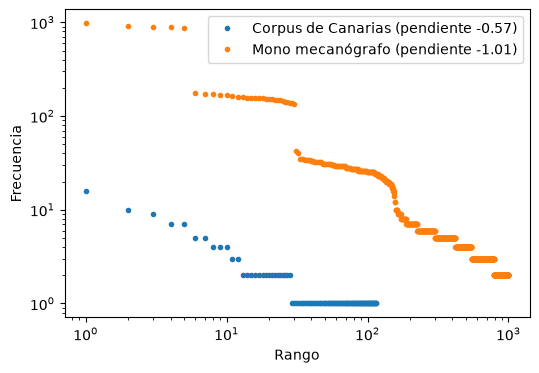

In [7]:
def pendiente_zipf(palabras, primeros=1000):
    frecuencias = np.array(sorted(Counter(palabras).values(), reverse=True), dtype=float)[:primeros]
    rangos = np.arange(1, len(frecuencias) + 1)
    x, y = np.log(rangos), np.log(frecuencias)
    pendiente, _ = np.polyfit(x, y, 1)
    a_mano = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
    assert math.isclose(pendiente, a_mano)
    return pendiente, rangos, frecuencias


rng = np.random.default_rng(36)
pulsaciones = "".join(rng.choice(list("abcde "), size=200_000))
palabras_mono = pulsaciones.split()

fig, ax = plt.subplots(figsize=(6, 4))
for nombre, lista in [("Corpus de Canarias", todas), ("Mono mecanógrafo", palabras_mono)]:
    s, r, f = pendiente_zipf(lista)
    print(f"{nombre:<20} {len(set(lista)):>6} palabras distintas, pendiente {s:.2f}")
    ax.loglog(r, f, ".", label=f"{nombre} (pendiente {s:.2f})")
ax.set_xlabel("Rango")
ax.set_ylabel("Frecuencia")
ax.legend()
plt.show()

## 7. Bolsa de palabras

Construir a mano la matriz documento-término: el vocabulario ordenado alfabéticamente con los términos de `terminos` y, en cada fila, cuántas veces aparece cada término en el documento. Compararla con `CountVectorizer` usando el mismo analizador. Mostrar el tamaño de la matriz, su proporción de ceros y los términos que aparecen en más documentos.

In [8]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

docs_terminos = [terminos(doc) for doc in CORPUS]
vocabulario = sorted({t for d in docs_terminos for t in d})
indice = {t: j for j, t in enumerate(vocabulario)}

conteos = np.zeros((len(CORPUS), len(vocabulario)), dtype=int)
for i, d in enumerate(docs_terminos):
    for t in d:
        conteos[i, indice[t]] += 1

contador = CountVectorizer(analyzer=terminos)
conteos_sk = contador.fit_transform(CORPUS).toarray()
assert list(contador.get_feature_names_out()) == vocabulario
assert (conteos == conteos_sk).all()

frecuencia_documental = (conteos > 0).sum(axis=0)
print("Matriz:", conteos.shape, f"ceros: {(conteos == 0).mean():.0%}")
print("En más documentos:", sorted(zip(vocabulario, frecuencia_documental.tolist()), key=lambda par: -par[1])[:6])

Matriz: (12, 87) ceros: 90%
En más documentos: [('alisios', 2), ('arena', 2), ('arrugadas', 2), ('barrancos', 2), ('blanca', 2), ('erupcion', 2)]


## 8. TF-IDF a mano

Calcular TF-IDF como lo hace `TfidfVectorizer` por defecto: la frecuencia del término en el documento multiplicada por $\operatorname{idf}(t) = \ln\frac{1 + n}{1 + \operatorname{df}(t)} + 1$, con $n$ documentos y $\operatorname{df}(t)$ documentos que contienen $t$, y cada fila normalizada a norma euclídea 1. Comprobar que coincide con `TfidfVectorizer` y mostrar el término de mayor y menor idf.

In [9]:
n = len(CORPUS)
idf = np.log((1 + n) / (1 + frecuencia_documental)) + 1
tfidf = conteos * idf
tfidf = tfidf / np.linalg.norm(tfidf, axis=1, keepdims=True)

vectorizador = TfidfVectorizer(analyzer=terminos)
tfidf_sk = vectorizador.fit_transform(CORPUS).toarray()
assert np.allclose(tfidf, tfidf_sk)
assert np.allclose(idf, vectorizador.idf_)
assert np.allclose(np.linalg.norm(tfidf, axis=1), 1)

print(f"Menor idf: {vocabulario[idf.argmin()]!r} ({idf.min():.3f}); mayor idf: {idf.max():.3f}, "
      f"compartido por {(idf == idf.max()).sum()} términos que solo salen en un documento")

Menor idf: 'alisios' (2.466); mayor idf: 2.872, compartido por 74 términos que solo salen en un documento


## 9. Similitud del coseno

La similitud del coseno entre dos vectores es $\cos\theta = \frac{u \cdot v}{\lVert u \rVert\, \lVert v \rVert}$. Calcular a mano la matriz de similitudes entre los doce documentos con TF-IDF, comprobarla con `cosine_similarity` y mostrar las tres parejas de documentos más parecidas con el comienzo de cada texto.

In [10]:
from sklearn.metrics.pairwise import cosine_similarity


def coseno(u, v):
    return float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))


similitud = np.array([[coseno(u, v) for v in tfidf] for u in tfidf])
assert np.allclose(similitud, cosine_similarity(tfidf))
assert np.allclose(similitud, tfidf @ tfidf.T)  # filas ya normalizadas

parejas = sorted(((similitud[i, j], i, j) for i in range(n) for j in range(i + 1, n)), reverse=True)
for s, i, j in parejas[:3]:
    print(f"{s:.3f}  {CORPUS[i][:40]!r:<44} {CORPUS[j][:40]!r}")

0.307  'Las playas de Fuerteventura tienen arena'   'La Graciosa es una isla tranquila: no ha'
0.251  '¿Sabías que el Teide es un volcán activo'   'La Palma vivió en 2021 la erupción del v'
0.178  'El bosque de laurisilva de Garajonay, en'   'El Hierro produce casi toda su electrici'


## 10. Un buscador

Crear `buscar(consulta, k)`, que transforme la consulta con el vectorizador TF-IDF ya ajustado y devuelva los `k` documentos más parecidos según el coseno, descartando los de similitud 0. Probarlo con varias consultas y comprobar el orden con una búsqueda por fuerza bruta que calcula la similitud documento a documento con la función `coseno`. ¿Por qué `comida típica` no encuentra el texto de las papas arrugadas y `plato típico` sí?

In [11]:
def buscar(consulta, k=3):
    q = vectorizador.transform([consulta]).toarray()[0]
    puntuaciones = tfidf @ q
    orden = np.argsort(-puntuaciones, kind="stable")[:k]
    return [(int(i), float(puntuaciones[i])) for i in orden if puntuaciones[i] > 0]


def buscar_fuerza_bruta(consulta, k=3):
    q = vectorizador.transform([consulta]).toarray()[0]
    if not q.any():
        return []
    resultados = [(i, coseno(d, q)) for i, d in enumerate(tfidf)]
    resultados = [r for r in resultados if r[1] > 0]
    return sorted(resultados, key=lambda r: -r[1])[:k]


for consulta in ["erupción de un volcán", "playas con viento", "plato típico", "comida típica", "Parlamento europeo"]:
    resultados = buscar(consulta)
    print(f"{consulta!r}:")
    for i, s in resultados:
        print(f"   {s:.3f}  {CORPUS[i][:60]}")
    if not resultados:
        print("   (sin resultados)")
    esperado = buscar_fuerza_bruta(consulta)
    assert [i for i, _ in resultados] == [i for i, _ in esperado]
    assert np.allclose([s for _, s in resultados], [s for _, s in esperado])

print("`típica` no es el mismo término que `típico`: sin raíces ni lematización, el buscador no los relaciona.")

'erupción de un volcán':
   0.592  ¿Sabías que el Teide es un volcán activo? Su última erupción
   0.424  La Palma vivió en 2021 la erupción del volcán de Tajogaite, 
'playas con viento':
   0.491  Las playas de Fuerteventura tienen arena blanca y un viento 
   0.208  La Graciosa es una isla tranquila: no hay carreteras asfalta
'plato típico':
   0.517  ¡Qué buenas están las papas arrugadas con mojo picón! Es el 
'comida típica':
   (sin resultados)
'Parlamento europeo':
   (sin resultados)
`típica` no es el mismo término que `típico`: sin raíces ni lematización, el buscador no los relaciona.


## 11. Palabras clave de cada documento

Extraer como palabras clave de cada documento los tres términos con mayor TF-IDF (desempatando por orden alfabético). Hacerlo con `np.argsort` sobre la fila y comprobarlo con `sorted` sobre parejas `(término, peso)`. Mostrar las palabras clave de cada isla o tema.

In [12]:
def palabras_clave(i, k=3):
    fila = tfidf[i]
    orden = np.lexsort((np.array(vocabulario), -fila))
    return [vocabulario[j] for j in orden[:k]]


for i, doc in enumerate(CORPUS):
    clave = palabras_clave(i)
    print(f"{i:>2}. {', '.join(clave):<36} {doc[:45]}")
    por_sorted = [t for t, _ in sorted(zip(vocabulario, tfidf[i]), key=lambda par: (-par[1], par[0]))[:3]]
    assert clave == por_sorted

 0. alto, centro, españa                 El Teide es el pico más alto de España y se l
 1. activo, ultima, erupcion             ¿Sabías que el Teide es un volcán activo? Su 
 2. ceniza, crateres, dejaron            En Lanzarote los volcanes de Timanfaya dejaro
 3. atrae, constante, fuerteventura      Las playas de Fuerteventura tienen arena blan
 4. asfaltadas, carreteras, graciosa     La Graciosa es una isla tranquila: no hay car
 5. conserva, cruza, gomero              En La Gomera se conserva el silbo gomero, un 
 6. bosque, garajonay, guarda            El bosque de laurisilva de Garajonay, en La G
 7. buenas, islas, mojo                  ¡Qué buenas están las papas arrugadas con moj
 8. caldo, cereales, gofio               El gofio es harina de cereales tostados y se 
 9. casas, cubrio, palma                 La Palma vivió en 2021 la erupción del volcán
10. agua, casi, central                  El Hierro produce casi toda su electricidad c
11. canaria, dunas, gran                 Gr

## 12. Colocaciones con información mutua

Una colocación es una pareja de palabras que aparece junta más de lo que cabría esperar por azar. Puntuar cada bigrama de términos contiguos (en la secuencia sin palabras vacías) con la información mutua puntual $\operatorname{PMI}(x, y) = \log_2 \frac{P(x, y)}{P(x)\,P(y)}$ y mostrar los bigramas que aparecen al menos dos veces ordenados por PMI. Comprobar el valor de uno de ellos calculándolo con los recuentos directamente.

In [13]:
secuencias = [terminos(doc) for doc in CORPUS]
unigramas = Counter(t for s in secuencias for t in s)
bigr = Counter(g for s in secuencias for g in ngramas(s, 2))
total_uni, total_bi = sum(unigramas.values()), sum(bigr.values())


def pmi(x, y):
    p_xy = bigr[x, y] / total_bi
    return math.log2(p_xy / ((unigramas[x] / total_uni) * (unigramas[y] / total_uni)))


candidatos = sorted(((pmi(x, y), x, y) for (x, y), c in bigr.items() if c >= 2), reverse=True)
for valor, x, y in candidatos:
    print(f"{x + ' ' + y:<18} PMI = {valor:.2f}  ({bigr[x, y]} veces)")

assert candidatos
_, x, y = candidatos[0]
directo = math.log2(bigr[x, y] * total_uni**2 / (total_bi * unigramas[x] * unigramas[y]))
assert math.isclose(candidatos[0][0], directo)

vientos alisios    PMI = 5.83  (2 veces)
papas arrugadas    PMI = 5.83  (2 veces)
arena blanca       PMI = 5.83  (2 veces)
